# Cold–warm metric: CW mean & basin warming

**What's in this notebook**

- Cold–warm mean metric across ERA5/JRA55-do forced ACCESS-OM2 experiments.
- Basin-mean warming.

_Split from `cw_metric.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [ ]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


# cw mean

In [3]:
cw_mean_cmip = xr.open_dataarray('/Users/isabelaconde/Desktop/data/cw_mean.nc').load()
# cw_mean

In [4]:
folder = "/Users/isabelaconde/Desktop/data/exp_percentiles"

for fname in os.listdir(folder):
    if fname.endswith(".nc"):
        var_name = os.path.splitext(fname)[0]
        globals()[var_name] = xr.open_dataarray(os.path.join(folder, fname))
        print(f"Loaded {var_name}")


Loaded jra55_percentiles
Loaded uas_vas_mean_trend_percentiles
Loaded all_trend_percentiles
Loaded cold_mean
Loaded rsds_rlds_trend_percentiles
Loaded huss_tas_trend_percentiles
Loaded era5_percentiles
Loaded era5_winds_percentiles
Loaded warm_mean
Loaded uas_vas_trend_percentiles


In [5]:
jra55_mean_cw = (jra55_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - jra55_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
era5_mean_cw = (era5_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - era5_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
uas_vas_mean_trend_mean_cw = (uas_vas_mean_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - uas_vas_mean_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
rsds_rlds_trend_mean_cw = (rsds_rlds_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - rsds_rlds_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
huss_tas_trend_mean_cw = (huss_tas_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - huss_tas_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
era5_winds_mean_cw = (era5_winds_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - era5_winds_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
uas_vas_trend_mean_cw = (uas_vas_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - uas_vas_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')


In [8]:
noaa_sst = xr.open_dataset('/Users/isabelaconde/Desktop/data/conde2025/NOAA_sst.mon.mean.nc').sst.sel(time = slice('1982','2017')).sel(lat = slice(-80,80))
noaa_sst_pacific = (pacific_mask(noaa_sst)*noaa_sst).sel(lat=slice(-20,20), lon = slice(100,300))
noaa_sst_percentiles = percentiles_xhist(noaa_sst_pacific)

noaa_mean_cw = (noaa_sst_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - noaa_sst_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
# noaa_mean_cw

In [9]:
# omip_models
# cw_omip
# lo = cw_mean.quantile(0.1, dim="ensem")
# hi = cw_mean.quantile(0.9, dim="run")

# cw_cmip_trim = cw_cmip #.where((cw_cmip >= lo) & (cw_cmip <= hi), drop=True)

df_cw_mean_cmip = (cw_mean_cmip).to_dataframe(name="value").reset_index()
df_cw_mean_cmip["group"] = "CMIP"


vals = [float(v.values) for v in cw_mean_omip.values()]   
df_mean_omip = pd.DataFrame({"value": vals})
df_mean_omip["group"] = "OMIP"

df_mean_all = pd.concat([df_cw_mean_cmip[["value","group"]], df_mean_omip], ignore_index=True)

NameError: name 'cw_mean_omip' is not defined

NameError: name 'transforms' is not defined

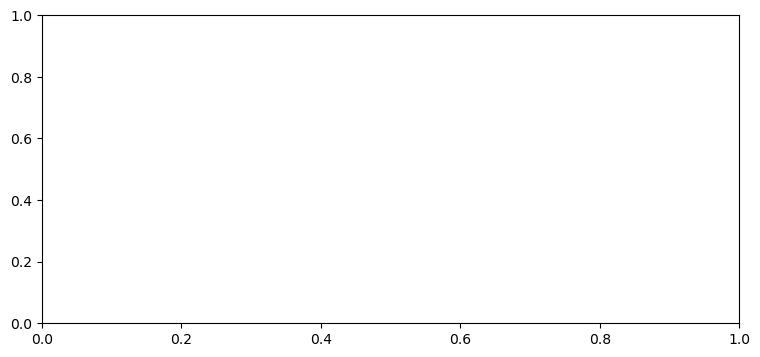

In [10]:

sources = ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = [ 'firebrick','darkviolet', 'cyan','b', 'violet', 'orange','limegreen', 'k']

obs_perturb_mean_df = pd.DataFrame({
    'Source': ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST'],
    'values': np.array([jra55_mean_cw.values,era5_mean_cw.values,uas_vas_trend_mean_cw.values,uas_vas_mean_trend_mean_cw.values,era5_winds_mean_cw.values, rsds_rlds_trend_mean_cw.values,
                        huss_tas_trend_mean_cw.values,  noaa_mean_cw.values])
})

obs_perturb_mean_df = obs_perturb_mean_df.rename(columns={"values": "value"})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

order = list(obs_perturb_mean_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_mean_df["group"].eq("NOAA OISST")

markers = ['s','o',  '^',  '<','D','v', 'P',  '*']  # last one is NOAA
# colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen',  'orange', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_mean_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group",
    y="value",
    ax=ax,
    marker="o",
    size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)
# sns.stripplot(
#     data=df_mean_all,
#     x="group",
#     y="value",
#     ax=ax,
#     palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
#     alpha=0.3,
#     jitter=0.25,
#     size=6
# )
# NOAA reference line
ax.axhline(y=float(noaa_mean_cw.values) , color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_mean_df = obs_perturb_mean_df.rename(columns={"values": "value"})  # if needed
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_mean_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    if (obs_perturb_mean_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C )')
plt.xticks(rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [11]:
sources = [
    'JRA55-do forced',
    'ERA5 forced',
    'JRA55-do forced with ERA5 uas, vas trend',
    'JRA55-do forced with ERA5 uas, vas trend and mean state',
    'JRA55-do forced with ERA5 uas, vas',
    'JRA55-do forced with ERA5 rsds, rlds trend',
    'JRA55-do forced with ERA5 huss, tas trend',
    'NOAA OISST'
]

colors = ['firebrick', 'darkviolet', 'cyan', 'b', 'violet', 'orange', 'limegreen', 'k']
markers = ['s', 'o', '^', '<', 'D', 'v', 'P', '*']   # NOAA = *

# -------------------------
# Trend dataframe
# -------------------------
obs_perturb_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        cw_jra55.values,
        cw_era5.values,
        cw_perturb_uas_vas.values,
        cw_perturb_winds_mean_trend.values,
        cw_perturb_winds.values,
        cw_perturb_rsds_rlds.values,
        cw_perturb_huss_tas.values,
        cw_noaa.values
    ]) * 10 * 12
})
obs_perturb_df["group"] = obs_perturb_df["Source"]

# -------------------------
# Mean dataframe
# -------------------------
obs_perturb_mean_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        jra55_mean_cw.values,
        era5_mean_cw.values,
        uas_vas_trend_mean_cw.values,
        uas_vas_mean_trend_mean_cw.values,
        era5_winds_mean_cw.values,
        rsds_rlds_trend_mean_cw.values,
        huss_tas_trend_mean_cw.values,
        noaa_mean_cw.values
    ])
})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

order = sources
pal = dict(zip(order, colors))

# marker/color maps
non_noaa_sources = [s for s in order if s != "NOAA OISST"]
noaa_source = "NOAA OISST"

marker_map = {}
color_map = {}

for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i]
    color_map[s] = colors[i]

marker_map[noaa_source] = markers[-1]
color_map[noaa_source] = colors[-1]

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(9, 8), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

ax_top, ax_bot = axes

# =========================
# Top: Trend
# =========================
trans_top = transforms.blended_transform_factory(ax_top.transAxes, ax_top.transData)

sns.violinplot(
    data=df_all, x="group", y="value",
    inner=None, ax=ax_top,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

sns.stripplot(
    data=df_means, x="group", y="value",
    ax=ax_top, marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

# NOAA reference line
ax_top.axhline(
    y=float(cw_noaa.values) * 10 * 12,
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

# obs/perturb points
for s in order:
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax_top,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55 lines only, no text labels on top panel
dy = 0.02 * (ax_bot.get_ylim()[1] - ax_bot.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
    ax_top.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
#     ax_bot.text(
#     0.99, y - dy, src,
#     transform=trans_bot,
#     ha="right", va="top",
#     color=pal[src], alpha=0.9
# )

# # ERA5 + JRA55 lines + labels only on bottom panel
# dy = 0.02 * (ax_bot.get_ylim()[1] - ax_bot.get_ylim()[0])
# for src in ["ERA5 forced", "JRA55-do forced"]:
#     y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
#     ax_bot.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
#     ax_bot.text(
#         0.99, y - dy, src,
#         transform=trans_bot,
#         ha="right", va="top",
#         color=pal[src], alpha=0.9
#     )


ax_top.set_xlabel('')
ax_top.set_ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
ax_top.tick_params(axis='x', labelbottom=False)

# =========================
# Bottom: Mean
# =========================
trans_bot = transforms.blended_transform_factory(ax_bot.transAxes, ax_bot.transData)

sns.violinplot(
    data=df_mean_all, x="group", y="value",
    inner=None, ax=ax_bot,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)
df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax_bot,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

# sns.stripplot(
#     data=df_mean_all, x="group", y="value",
#     ax=ax_bot,
#     palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
#     alpha=0.3, jitter=0.25, size=6
# )

# NOAA reference line
ax_bot.axhline(
    y=float(noaa_mean_cw.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

# obs/perturb points
for s in order:
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax_bot,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55 lines + labels only on bottom panel
dy = 0.02 * (ax_bot.get_ylim()[1] - ax_bot.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
    ax_bot.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")


ax_bot.set_xlabel('')
ax_bot.set_ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C)')

bottom_labels = [t.get_text() for t in ax_bot.get_xticklabels()]
ax_bot.set_xticklabels(bottom_labels, rotation=30, ha="right")

# hide top x labels
ax_top.set_xlabel('')
ax_top.tick_params(axis='x', labelbottom=False)
plt.show()

outpath = "/Users/isabelaconde/Desktop/cw_1982-2017_combined.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

NameError: name 'cw_jra55' is not defined

# basin warming

In [12]:
# warmest 50% mean only
basin_omip = {}
for da in mod_labs:
    basin_omip[da] = percentiles_omip_trend[da].sel(area=slice(0, 1)).mean(dim="area")*10*12
print("omip calculated")

basin_cmip = DA_all.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("cmip calculated")

basin_noaa = noaa_sst_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("noaa calculated")

basin_jra55 = control_percent_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_era5  = era5_percent_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12

basin_perturb_uas_vas   = perturb_percent_era5_uas_vas_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_huss_tas  = perturb_percent_era5_huss_tas_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_rsds_rlds = perturb_percent_era5_rsds_rlds_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_winds     = perturb_percent_era5_winds.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_all       = perturb_percent_all_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
# warm50_cm2 = cm2_percent_trend.sel(area=slice(0.5, 1)).mean(dim="area")
basin_perturb_winds_mean_trend = perturb_percent_winds_mean_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("perturbation calculated")


NameError: name 'mod_labs' is not defined

In [13]:
df_basin_cmip = (basin_cmip).to_dataframe(name="value").reset_index()
df_basin_cmip["group"] = "CMIP"


vals = [float(v.values) for v in basin_omip.values()]   
df_basin_omip = pd.DataFrame({"value": vals})
df_basin_omip["group"] = "OMIP"

df_basin_all = pd.concat([df_basin_cmip[["value","group"]], df_basin_omip], ignore_index=True)

NameError: name 'basin_cmip' is not defined

In [14]:

sources = ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = [ 'firebrick','darkviolet', 'cyan','b', 'violet', 'orange','limegreen', 'k']

obs_perturb_basin_df = pd.DataFrame({
    'Source': ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST'],
    'values': np.array([basin_jra55.values,basin_era5.values,basin_perturb_uas_vas.values,basin_perturb_winds_mean_trend.values,basin_perturb_winds.values, basin_perturb_rsds_rlds.values,
                        basin_perturb_huss_tas.values,  basin_noaa.values])
})

obs_perturb_basin_df = obs_perturb_basin_df.rename(columns={"values": "value"})
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

order = list(obs_perturb_basin_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_basin_df["group"].eq("NOAA OISST")

markers = ['s','o',  '^',  '<','D','v', 'P',  '*']  # last one is NOAA
# colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen',  'orange', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_basin_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
df_mean = df_basin_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group",
    y="value",
    ax=ax,
    marker="o",
    size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

# NOAA reference line
ax.axhline(y=float(basin_noaa.values) , color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_basin_df = obs_perturb_basin_df.rename(columns={"values": "value"})  # if needed
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_basin_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    if (obs_perturb_basin_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y + dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Tropical Pacific SST ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/trop_pa_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

NameError: name 'basin_jra55' is not defined

In [ ]:

# -------------------------
# Common styling inputs
# -------------------------
sources = [
    'JRA55-do forced',
    'ERA5 forced',
    'JRA55-do forced with ERA5 uas, vas trend',
    'JRA55-do forced with ERA5 uas, vas trend and mean state',
    'JRA55-do forced with ERA5 uas, vas',
    'JRA55-do forced with ERA5 rsds, rlds trend',
    'JRA55-do forced with ERA5 huss, tas trend',
    'NOAA OISST'
]

colors = ['firebrick', 'darkviolet', 'cyan', 'b', 'violet', 'orange', 'limegreen', 'k']
markers = ['s', 'o', '^', '<', 'D', 'v', 'P', '*']   # NOAA = *

order = sources
pal = dict(zip(order, colors))

# -------------------------
# Trend dataframe
# -------------------------
obs_perturb_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        cw_jra55.values,
        cw_era5.values,
        cw_perturb_uas_vas.values,
        cw_perturb_winds_mean_trend.values,
        cw_perturb_winds.values,
        cw_perturb_rsds_rlds.values,
        cw_perturb_huss_tas.values,
        cw_noaa.values
    ]) * 10 * 12
})
obs_perturb_df["group"] = obs_perturb_df["Source"]

# -------------------------
# Basin mean trend dataframe
# -------------------------
obs_perturb_basin_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        basin_jra55.values,
        basin_era5.values,
        basin_perturb_uas_vas.values,
        basin_perturb_winds_mean_trend.values,
        basin_perturb_winds.values,
        basin_perturb_rsds_rlds.values,
        basin_perturb_huss_tas.values,
        basin_noaa.values
    ])
})
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

# -------------------------
# Mean dataframe
# -------------------------
obs_perturb_mean_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        jra55_mean_cw.values,
        era5_mean_cw.values,
        uas_vas_trend_mean_cw.values,
        uas_vas_mean_trend_mean_cw.values,
        era5_winds_mean_cw.values,
        rsds_rlds_trend_mean_cw.values,
        huss_tas_trend_mean_cw.values,
        noaa_mean_cw.values
    ])
})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

# -------------------------
# Marker/color maps
# -------------------------
non_noaa_sources = [s for s in order if s != "NOAA OISST"]
noaa_source = "NOAA OISST"

marker_map = {}
color_map = {}

for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i]
    color_map[s] = colors[i]

marker_map[noaa_source] = markers[-1]
color_map[noaa_source] = colors[-1]

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(
    nrows=3, ncols=1, figsize=(9, 10), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

ax_top, ax_mid, ax_bot = axes

# =========================
# Top: C-W trend
# =========================
sns.violinplot(
    data=df_all, x="group", y="value",
    order=["CMIP", "OMIP"],
    inner=None, ax=ax_top,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

sns.stripplot(
    data=df_means, x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax_top, marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax_top.axhline(
    y=float(cw_noaa.values) * 10 * 12,
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax_top,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
    ax_top.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax_top.set_xlabel('')
ax_top.set_ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
ax_top.tick_params(axis='x', labelbottom=False)

# =========================
# Middle: Basin SST trend
# =========================
sns.violinplot(
    data=df_basin_all, x="group", y="value",
    order=["CMIP", "OMIP"],
    inner=None, ax=ax_mid,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_basin_mean = df_basin_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_basin_mean,
    x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax_mid,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax_mid.axhline(
    y=float(basin_noaa.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax_mid,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == src, "value"].iloc[0])
    ax_mid.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax_mid.set_xlabel('')
ax_mid.set_ylabel(r'Trend of Tropical Pacific SST ($^{\circ}$C 10yr$^{-1}$)')
ax_mid.tick_params(axis='x', labelbottom=False)

# =========================
# Bottom: Mean C-W gradient
# =========================
trans_bot = transforms.blended_transform_factory(ax_bot.transAxes, ax_bot.transData)

sns.violinplot(
    data=df_mean_all, x="group", y="value",
    order=["CMIP", "OMIP"],
    inner=None, ax=ax_bot,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax_bot,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax_bot.axhline(
    y=float(noaa_mean_cw.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax_bot,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

dy = 0.02 * (ax_bot.get_ylim()[1] - ax_bot.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
    ax_bot.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
    # ax_bot.text(
    #     0.99, y - dy, src,
    #     transform=trans_bot,
    #     ha="right", va="top",
    #     color=pal[src], alpha=0.9
    # )

ax_bot.set_xlabel('')
ax_bot.set_ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C)')

bottom_labels = [t.get_text() for t in ax_bot.get_xticklabels()]
ax_bot.set_xticklabels(bottom_labels, rotation=30, ha="right")

plt.show()

outpath = "/Users/isabelaconde/Desktop/cw_1982-2017_combined.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [ ]:
sources = [
    'JRA55-do forced',
    'ERA5 forced',
    'JRA55-do forced with ERA5 uas, vas trend',
    'JRA55-do forced with ERA5 uas, vas trend and mean state',
    'JRA55-do forced with ERA5 uas, vas',
    'JRA55-do forced with ERA5 rsds, rlds trend',
    'JRA55-do forced with ERA5 huss, tas trend',
    'NOAA OISST'
]

colors = ['firebrick', 'darkviolet', 'cyan', 'b', 'violet', 'orange', 'limegreen', 'k']
markers = ['s', 'o', '^', '<', 'D', 'v', 'P', '*']   # NOAA = *

order = sources
pal = dict(zip(order, colors))

# -------------------------
# Tropical Pacific SST trend dataframe
# -------------------------
obs_perturb_basin_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        basin_jra55.values,
        basin_era5.values,
        basin_perturb_uas_vas.values,
        basin_perturb_winds_mean_trend.values,
        basin_perturb_winds.values,
        basin_perturb_rsds_rlds.values,
        basin_perturb_huss_tas.values,
        basin_noaa.values
    ])
})
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

# -------------------------
# Cold-warm trend dataframe
# -------------------------
obs_perturb_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        cw_jra55.values,
        cw_era5.values,
        cw_perturb_uas_vas.values,
        cw_perturb_winds_mean_trend.values,
        cw_perturb_winds.values,
        cw_perturb_rsds_rlds.values,
        cw_perturb_huss_tas.values,
        cw_noaa.values
    ]) * 10 * 12
})
obs_perturb_df["group"] = obs_perturb_df["Source"]

# -------------------------
# Cold-warm mean dataframe
# -------------------------
obs_perturb_mean_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        jra55_mean_cw.values,
        era5_mean_cw.values,
        uas_vas_trend_mean_cw.values,
        uas_vas_mean_trend_mean_cw.values,
        era5_winds_mean_cw.values,
        rsds_rlds_trend_mean_cw.values,
        huss_tas_trend_mean_cw.values,
        noaa_mean_cw.values
    ])
})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

# -------------------------
# marker / colour maps
# -------------------------
non_noaa_sources = [s for s in order if s != "NOAA OISST"]
noaa_source = "NOAA OISST"

marker_map = {}
color_map = {}

for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i]
    color_map[s] = colors[i]

marker_map[noaa_source] = markers[-1]
color_map[noaa_source] = colors[-1]

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(
    nrows=3, ncols=1, figsize=(9, 9), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

ax1, ax2, ax3 = axes

# =====================================================
# Panel 1: Trend of tropical Pacific SST
# =====================================================
sns.violinplot(
    data=df_basin_all, x="group", y="value",
    inner=None, ax=ax1,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_basin_mean = df_basin_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_basin_mean,
    x="group", y="value",
    ax=ax1,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax1.axhline(
    y=float(basin_noaa.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax1,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == src, "value"].iloc[0])
    ax1.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax1.set_xlabel('')
ax1.set_ylabel(r'Trend of Tropical Pacific SST ($^{\circ}$C 10yr$^{-1}$)')
ax1.tick_params(axis='x', labelbottom=False)

# =====================================================
# Panel 2: Trend of cold-warm gradient
# =====================================================
sns.violinplot(
    data=df_all, x="group", y="value",
    inner=None, ax=ax2,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_trend_mean = df_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_trend_mean,
    x="group", y="value",
    ax=ax2,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax2.axhline(
    y=float(cw_noaa.values) * 10 * 12,
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax2,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
    ax2.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax2.set_xlabel('')
ax2.set_ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
ax2.tick_params(axis='x', labelbottom=False)

# =====================================================
# Panel 3: Mean cold-warm gradient
# =====================================================
sns.violinplot(
    data=df_mean_all, x="group", y="value",
    inner=None, ax=ax3,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax3,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax3.axhline(
    y=float(noaa_mean_cw.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax3,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
    ax3.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax3.set_xlabel('')
ax3.set_ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C)')

bottom_labels = [t.get_text() for t in ax3.get_xticklabels()]
ax3.set_xticklabels(bottom_labels, rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/three_panels_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature

sst = noaa_sst.isel(time =0)

def pacific_mask(sst):

    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130]
    LatsPts_pos = [-20,-10,-5,10,20,20,15,15,10,5,-20,-20]

    polygon = np.array(list(zip(LonsPts_pos, LatsPts_pos)))

    xv, yv = sst.lon, sst.lat
    lon2d, lat2d = np.meshgrid(xv, yv)

    points = np.hstack((
        lon2d.reshape((-1,1)),
        lat2d.reshape((-1,1))
    ))

    path = mpath.Path(polygon)

    mask = path.contains_points(points)
    mask.shape = lon2d.shape

    mask = mask.astype(float)
    mask[mask == 0] = np.nan

    return mask


# example global grid
lon = np.arange(0, 360, 1)
lat = np.arange(-90, 91, 1)

class Dummy:
    pass

sst = Dummy()
sst.lon = lon
sst.lat = lat

mask = pacific_mask(sst)

# plotting
proj = ccrs.PlateCarree(central_longitude=180)

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=proj)

ax.set_global()

im = ax.pcolormesh(
    lon,
    lat,
    mask,
    transform=ccrs.PlateCarree(),
)

ax.coastlines()
ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

plt.title("Pacific Mask Schematic")

plt.show()

In [ ]:

# Pacific mask polygon
LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130]
LatsPts_pos = [-20,-10,-5,10,20,20,15,15,10,5,-20,-20]

# plotting
proj = ccrs.PlateCarree(central_longitude=180)

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=proj)

ax.set_global()

# draw polygon outline
ax.plot(
    LonsPts_pos,
    LatsPts_pos,
    color='indianred',
    linewidth=2,
    transform=ccrs.PlateCarree()
)

ax.coastlines(linewidth=0.8)

# paler continents
ax.add_feature(
    cfeature.LAND,
    facecolor='0.92',
    edgecolor='none'
)

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

plt.title("Pacific Mask")


plt.savefig(
    os.path.expanduser("~/Desktop/pacific_mask_schematic.pdf"),
    bbox_inches="tight"
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# start/end values
start_year = 1982
end_year = 2017

x = [start_year, end_year]
y = [0, 100800]

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(x, y, linewidth=2, color = 'indianred')

# evenly spaced ticks
ticks = np.linspace(start_year, end_year, 8)

ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t)}" for t in ticks])

# angle labels
# plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


ax.set_xlabel("Time at 3 hourly time steps")
ax.set_ylabel("Scaler value")

ax.set_title("Linear Scaling")



plt.savefig(
    os.path.expanduser("~/Desktop/scaler_schematic.pdf"),
    bbox_inches="tight"
)

In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
